# DS2002 Midterm: Walmart Hurricane Analytics

**Solo project, Kabir Minhas (GitHub: Kminhas21).** One notebook, run top to bottom: data loading, cleaning pipeline, decision log, SKU consolidation, weather API, Questions 1-5, reflection.

**Weather source:** Open-Meteo historical archive, base URL `https://archive-api.open-meteo.com/v1/archive` (free, no key). Hourly weather is requested in UTC and converted to US Eastern to match the sales timestamps (naive local time).

**Conventions:** Baseline window = Sept 1-15 (flat period); surge window = Sept 19-25, the 7 days before landfall day (Sept 26, Hurricane Helene, an external fact not in the data). Rows with no timestamp cannot be placed in any window and are excluded from date-based work.

## 1. Data loading

All four CSVs are loaded with pandas, both SQLite tables are read with `sqlite3`, and the weather is pulled from the API in section 5. The profile below is the messy data before any cleaning.

In [1]:
import os
import pandas as pd
import numpy as np

DATA_DIR = next(d for d in ('data', '../data', '../../data') if os.path.isdir(d))
MISSING_TOKENS = {'', 'null', 'n/a', 'na', 'nan', 'none'}
DECISION_LOG = []

def log_decision(step, decision, rows_touched, rows_before=None, rows_after=None):
    DECISION_LOG.append({'step': step, 'decision': decision, 'rows_touched': int(rows_touched),
                         'rows_before': rows_before, 'rows_after': rows_after})


In [2]:
import sqlite3

tx_raw = pd.read_csv(os.path.join(DATA_DIR, 'walmart_transactions.csv'), dtype=str)
stores_raw = pd.read_csv(os.path.join(DATA_DIR, 'store_locations.csv'))
catalog = pd.read_csv(os.path.join(DATA_DIR, 'product_catalog (1).csv'))
dcs = pd.read_csv(os.path.join(DATA_DIR, 'distribution_centers.csv'))
con = sqlite3.connect(os.path.join(DATA_DIR, 'inventory_and_sales.db'))
daily_sales_raw = pd.read_sql('SELECT * FROM daily_sales_summary', con)
inventory_raw = pd.read_sql('SELECT * FROM inventory_levels', con)
con.close()

for name, df in [('walmart_transactions', tx_raw), ('store_locations', stores_raw), ('product_catalog', catalog),
                 ('distribution_centers', dcs), ('daily_sales_summary (sqlite)', daily_sales_raw), ('inventory_levels (sqlite)', inventory_raw)]:
    print(f'=== {name}: {len(df):,} rows x {len(df.columns)} columns | nulls {int(df.isnull().sum().sum())} | exact duplicate rows {int(df.duplicated().sum())}')
print()
print('transactions: distinct store_id', tx_raw['store_id'].nunique(), '| category', tx_raw['category'].nunique(),
      '| sku', tx_raw['sku'].nunique(), '| product_name', tx_raw['product_name'].nunique(), '| missing timestamps', int(tx_raw['timestamp'].isna().sum()))


=== walmart_transactions: 25,562 rows x 8 columns | nulls 886 | exact duplicate rows 30
=== store_locations: 14 rows x 8 columns | nulls 2 | exact duplicate rows 0
=== product_catalog: 45 rows x 7 columns | nulls 18 | exact duplicate rows 0
=== distribution_centers: 5 rows x 8 columns | nulls 1 | exact duplicate rows 0
=== daily_sales_summary (sqlite): 3,600 rows x 5 columns | nulls 0 | exact duplicate rows 0
=== inventory_levels (sqlite): 4,320 rows x 6 columns | nulls 626 | exact duplicate rows 0

transactions: distinct store_id 60 | category 37 | sku 45 | product_name 63 | missing timestamps 886


## 2. Cleaning pipeline

One function per cleaning decision, each logging what it did. Row counts before and after are printed; the store join is checked to lose no rows.

In [3]:
CATEGORY_MAP = {
    'alcohol': 'Alcohol', 'alcoholic beverages': 'Alcohol',
    'baby': 'Baby', 'baby products': 'Baby',
    'breakfast': 'Breakfast', 'breakfast foods': 'Breakfast',
    'electronics': 'Electronics',
    'emergency': 'Emergency', 'emergency supplies': 'Emergency',
    'entertainment': 'Entertainment', 'games & entertainment': 'Entertainment',
    'grocery': 'Grocery', 'groceries': 'Grocery',
    'health': 'Health', 'health & wellness': 'Health',
    'household': 'Household', 'household essentials': 'Household',
    'snacks': 'Snacks',
}
TS_FORMATS = ['%Y-%m-%d %H:%M:%S', '%Y-%m-%dT%H:%M:%S', '%m/%d/%Y %H:%M',
              '%d-%b-%Y %H:%M', '%m-%d-%Y %H:%M:%S']

def load_transactions():
    return pd.read_csv(os.path.join(DATA_DIR, 'walmart_transactions.csv'), dtype=str)

def standardize_missing(df):
    """Strip whitespace; turn '', NULL, N/A, NaN... into real NaN."""
    out = df.copy()
    touched = 0
    for c in out.columns:
        s = out[c].str.strip()
        newly_na = s.str.lower().isin(MISSING_TOKENS) & out[c].notna()
        touched += int(newly_na.sum())
        out[c] = s.mask(newly_na)
    log_decision('missing', 'strip whitespace; blank/NULL/N-A tokens -> NaN (cells, not rows)', touched, len(df), len(out))
    return out

def remove_duplicates(df):
    n0 = len(df)
    out = df.drop_duplicates()
    log_decision('duplicates', 'drop exact duplicate rows (keep first)', n0 - len(out), n0, len(out))
    n1 = len(out)
    out = out.drop_duplicates('transaction_id')
    log_decision('duplicates', 'drop repeated transaction_id (keep first)', n1 - len(out), n1, len(out))
    return out

def clean_unit_price(df):
    out = df.copy()
    raw = out['unit_price']
    dollar = int(raw.str.contains('$', regex=False, na=False).sum())
    out['unit_price'] = pd.to_numeric(raw.str.replace('$', '', regex=False).str.replace(',', '', regex=False), errors='coerce')
    bad = int(out['unit_price'].isna().sum() - raw.isna().sum())
    log_decision('unit_price', "remove '$', cast text -> float", dollar, len(df), len(out))
    log_decision('unit_price', 'values that still failed numeric cast -> NaN', bad, len(df), len(out))
    return out

def clean_quantity(df):
    out = df.copy()
    out['quantity'] = pd.to_numeric(out['quantity'], errors='coerce')
    n0 = len(out)
    out = out[out['quantity'] > 0]
    log_decision('quantity', 'drop rows with negative/zero/unparseable quantity (entry errors; sign-flip not assumed)', n0 - len(out), n0, len(out))
    return out

def parse_timestamps(df):
    out = df.copy()
    ts = pd.Series(pd.NaT, index=out.index, dtype='datetime64[ns]')
    for fmt in TS_FORMATS:
        todo = ts.isna() & out['timestamp'].notna()
        ts[todo] = pd.to_datetime(out.loc[todo, 'timestamp'], format=fmt, errors='coerce')
    unparsed = int((ts.isna() & out['timestamp'].notna()).sum())
    missing = int(out['timestamp'].isna().sum())
    out['timestamp'] = ts
    log_decision('timestamp', f'parse {len(TS_FORMATS)} mixed formats into one datetime (naive local time); {unparsed} unparseable', int(ts.notna().sum()), len(df), len(out))
    log_decision('timestamp', 'missing timestamps kept (NaT) but excluded from any date-based analysis; not imputed', missing, len(df), len(out))
    return out

def clean_store_id(df):
    out = df.copy()
    raw = out['store_id']
    out['store_id'] = (raw.str.upper().str.replace('_', '-', regex=False)
                          .str.replace(r'^FL-?(\d{3})$', r'FL-\1', regex=True))
    log_decision('store_id', "uppercase, strip, '_'/missing '-' -> canonical 'FL-###'", int((raw != out['store_id']).sum()), len(df), len(out))
    return out

def clean_category(df):
    out = df.copy()
    raw = out['category']
    out['category'] = raw.str.lower().map(CATEGORY_MAP)
    log_decision('category', f'collapse {raw.nunique()} spellings into {out["category"].nunique()} canonical categories', int((raw != out['category']).sum()), len(df), len(out))
    return out

def clean_transactions():
    DECISION_LOG.clear()
    df = load_transactions()
    for step in (standardize_missing, remove_duplicates, clean_unit_price, clean_quantity,
                 parse_timestamps, clean_store_id, clean_category):
        df = step(df)
    df['product_name_raw'] = df['product_name']
    return df.reset_index(drop=True)

def clean_stores():
    s = pd.read_csv(os.path.join(DATA_DIR, 'store_locations.csv'), dtype={'zip_code': str})
    n0 = len(s)
    s['store_id'] = (s['store_id'].str.strip().str.upper().str.replace('_', '-', regex=False)
                     .str.replace(r'^FL-?(\d{3})$', r'FL-\1', regex=True))
    s = s.drop_duplicates('store_id').reset_index(drop=True)
    log_decision('stores', 'canonicalise store_id and drop duplicate store rows', n0 - len(s), n0, len(s))
    changed = int((s['state'] != 'FL').sum())
    s['state'] = 'FL'
    log_decision('stores', "normalise state ('Florida', 'Fla.') to 'FL'", changed, len(s), len(s))
    # Tallahassee has no coordinates; approximate city-centre values filled in (needed for the weather call)
    fill = {'FL-619': (30.4383, -84.2807)}
    for sid, (lat, lon) in fill.items():
        m = (s['store_id'] == sid) & s['latitude'].isna()
        s.loc[m, ['latitude', 'longitude']] = (lat, lon)
    log_decision('stores', 'fill missing lat/lon for Tallahassee (FL-619) with approximate city-centre coordinates', len(fill), len(s), len(s))
    return s


In [4]:
raw_tx = load_transactions()
print('transactions rows before cleaning:', len(raw_tx))
tx_clean = clean_transactions()
print('transactions rows after cleaning: ', len(tx_clean), f'({len(raw_tx) - len(tx_clean)} rows removed)')
stores = clean_stores()
joined = tx_clean.merge(stores, on='store_id', how='left', validate='many_to_one', indicator=True)
assert len(joined) == len(tx_clean) and (joined['_merge'] == 'both').all(), 'some transactions did not match a store'
print('store join check: all', len(joined), 'transactions matched one of', len(stores), 'stores')
ts = tx_clean['timestamp'].dropna()
assert ts.dt.year.eq(2024).all() and ts.dt.month.eq(9).all()
assert tx_clean['transaction_id'].is_unique and (tx_clean['quantity'] > 0).all()
tx_clean.head()


transactions rows before cleaning: 25562


transactions rows after cleaning:  25402 (160 rows removed)
store join check: all 25402 transactions matched one of 12 stores


,transaction_id,store_id,timestamp,sku,product_name,category,quantity,unit_price,product_name_raw
0,TXN012636,FL-710,2024-09-24 09:48:13,PNUTBTR-16,PEANUT BUTTER,Grocery,1,3.15,PEANUT BUTTER
1,TXN000759,FL-412,2024-09-13 20:30:20,CNSOUP-01,CANNED SOUP,Grocery,1,2.02,CANNED SOUP
2,TXN003338,FL-105,2024-09-17 10:06:00,TOILETPAPER12,Toilet Paper 12-Roll,Household,2,10.47,Toilet Paper 12-Roll
3,TXN025020,FL-330,2024-09-11 06:29:08,ROKU-STD,Roku Streaming Stick,Electronics,1,28.59,Roku Streaming Stick
4,TXN015797,FL-302,2024-09-26 15:59:42,BEER-24,Light Beer 24pk,Alcohol,3,18.82,Light Beer 24pk


Sanity chart of daily order volume. A zero day or a day many times the norm would point at a cleaning bug rather than the hurricane.

days: 30 | zero days: 0 | rows used 24,521 of 25,402 (the rest have no timestamp)


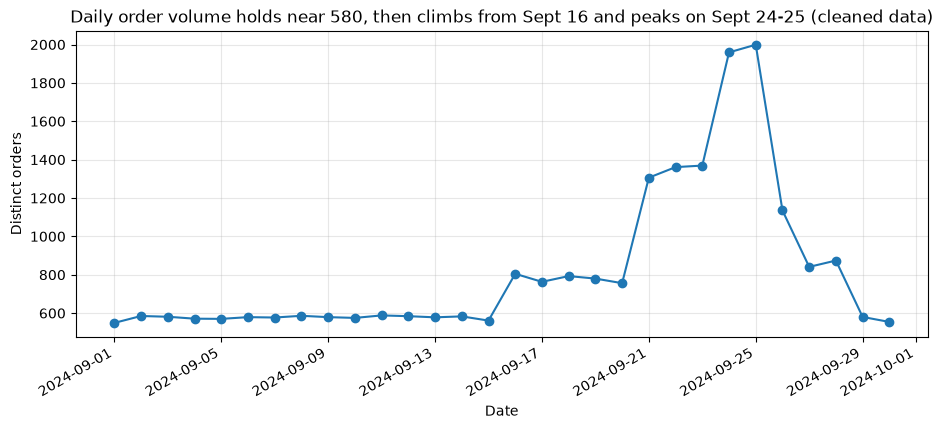

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns

dated = tx_clean.dropna(subset=['timestamp']).assign(day=lambda x: x['timestamp'].dt.normalize())
daily = dated.groupby('day')['transaction_id'].nunique()
print(f'days: {len(daily)} | zero days: {int((daily == 0).sum())} | rows used {len(dated):,} of {len(tx_clean):,} (the rest have no timestamp)')

fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(daily.index, daily.values, marker='o')
ax.set_title('Daily order volume holds near 580, then climbs from Sept 16 and peaks on Sept 24-25 (cleaned data)')
ax.set_xlabel('Date'); ax.set_ylabel('Distinct orders')
ax.grid(alpha=.3); fig.autofmt_xdate(); plt.show()


## 3. Decision log

Every cleaning decision, what it did, and how many rows (or cells, for the missing-value step) it touched.

In [6]:
pd.set_option('display.max_colwidth', 110)
pd.set_option('display.width', 200)
decision_log = pd.DataFrame(DECISION_LOG)
decision_log

,step,decision,rows_touched,rows_before,rows_after
0,missing,"strip whitespace; blank/NULL/N-A tokens -> NaN (cells, not rows)",0,25562,25562
1,duplicates,drop exact duplicate rows (keep first),30,25562,25532
2,duplicates,drop repeated transaction_id (keep first),0,25532,25532
3,unit_price,"remove '$', cast text -> float",3026,25532,25532
4,unit_price,values that still failed numeric cast -> NaN,0,25532,25532
5,quantity,drop rows with negative/zero/unparseable quantity (entry errors; sign-flip not assumed),130,25532,25402
6,timestamp,parse 5 mixed formats into one datetime (naive local time); 0 unparseable,24521,25402,25402
7,timestamp,missing timestamps kept (NaT) but excluded from any date-based analysis; not imputed,881,25402,25402
8,store_id,"uppercase, strip, '_'/missing '-' -> canonical 'FL-###'",3590,25402,25402
9,category,collapse 37 spellings into 10 canonical categories,18649,25402,25402


**Judgement calls:** negative quantities were dropped rather than sign-flipped (nothing marks them as returns); the rows with no timestamp were kept but excluded from date-based work instead of being imputed; Tallahassee's missing store coordinates were filled with approximate city-centre values (needed for the weather call).

## 4. SKU consolidation

The same product appears under several SKUs and name spellings. SKUs that share any product name are merged into one canonical product (union-find over the SKU/name graph).

In [7]:
def build_sku_map(df):
    """Group SKUs that share product names (union-find over sku <-> normalized name)."""
    names = df[['sku', 'product_name']].dropna().assign(name=lambda d: d['product_name'].str.lower().str.strip())
    parent = {}
    def find(x):
        parent.setdefault(x, x)
        while parent[x] != x:
            parent[x] = parent[parent[x]]
            x = parent[x]
        return x
    for sku, name in names[['sku', 'name']].drop_duplicates().itertuples(index=False):
        parent[find(('sku', sku))] = find(('name', name))
    names['group'] = names['sku'].map(lambda s: find(('sku', s)))
    sku_group = names.drop_duplicates('sku').set_index('sku')['group']
    ids = {g: i + 1 for i, g in enumerate(sorted(sku_group.unique(), key=str))}
    # canonical name = most common mixed-case product_name in the group (skips ALL-CAPS / lowercase variants)
    mixed = names[~names['product_name'].str.isupper() & ~names['product_name'].str.islower()]
    top_name = (mixed.assign(pid=mixed['group'].map(ids)).groupby('pid')['product_name']
                .agg(lambda s: s.str.strip().value_counts().idxmax()))
    out = pd.DataFrame({'sku': sku_group.index, 'canonical_id': sku_group.map(ids).values})
    out['canonical_name'] = out['canonical_id'].map(top_name)
    return out.sort_values(['canonical_id', 'sku']).reset_index(drop=True)


In [8]:
sku_map = build_sku_map(tx_clean)
sizes = sku_map.groupby('canonical_name').size().sort_values(ascending=False)
print('distinct SKUs:', sku_map['sku'].nunique(), '-> canonical products:', sku_map['canonical_id'].nunique(),
      '| largest family:', sizes.index[0], f'({sizes.iloc[0]} SKUs)')
sku_map


distinct SKUs: 45 -> canonical products: 20 | largest family: Pop-Tarts Strawberry (4 SKUs)


,sku,canonical_id,canonical_name
0,DIAP-S3,1,Diapers Size 3
1,DIAPERS-3,1,Diapers Size 3
2,BABYFORMULA,2,Infant Formula
3,BFORM-01,2,Infant Formula
4,BAT-AA4,3,AA Batteries 4-Pack
5,BATT-100,3,AA Batteries 4-Pack
6,BATT_AA_4PK,3,AA Batteries 4-Pack
7,BEER-24,4,Light Beer 24pk
8,LTBEER24,4,Light Beer 24pk
9,WATER24PK,5,Bottled Water 24-Pack


## 5. Weather API

One call per store location (12), hourly temperature, wind speed, wind gusts, precipitation and sea-level pressure, with retries and exponential backoff; the function raises if it never succeeds. Timestamps are requested in UTC and converted to US Eastern.

In [9]:
import time, requests

WEATHER_URL = 'https://archive-api.open-meteo.com/v1/archive'
WEATHER_VARS = ['temperature_2m', 'wind_speed_10m', 'wind_gusts_10m', 'precipitation', 'pressure_msl']

def fetch_weather(lat, lon, start, end, retries=4, backoff=2):
    """Hourly weather from Open-Meteo for one point. Retries with exponential backoff and fails loudly."""
    params = dict(latitude=lat, longitude=lon, start_date=start, end_date=end,
                  hourly=','.join(WEATHER_VARS), timezone='UTC')   # request UTC, convert ourselves
    last = None
    for attempt in range(1, retries + 1):
        try:
            r = requests.get(WEATHER_URL, params=params, timeout=30)
            r.raise_for_status()
            df = pd.DataFrame(r.json()['hourly']).rename(columns={'time': 'time_utc'})
            df['time_utc'] = pd.to_datetime(df['time_utc'])
            df['time_local'] = (df['time_utc'].dt.tz_localize('UTC')
                                .dt.tz_convert('America/New_York').dt.tz_localize(None))
            df['source'] = 'open-meteo-archive'
            return df
        except (requests.RequestException, KeyError, ValueError) as e:
            last = e
            print(f'attempt {attempt}/{retries} failed: {e}')
            time.sleep(backoff ** attempt)
    raise RuntimeError(f'weather API failed after {retries} attempts: {last}')


In [10]:
frames = []
for r in stores.itertuples():
    w = fetch_weather(r.latitude, r.longitude, '2024-08-31', '2024-10-01')
    w.insert(0, 'store_id', r.store_id)
    frames.append(w)
weather = pd.concat(frames, ignore_index=True)
weather = weather[(weather['time_local'] >= '2024-09-01') & (weather['time_local'] < '2024-10-01')]
print('data source:', weather['source'].unique().tolist(), '(live API call, no fallback file used)')


weather.head()

data source: ['open-meteo-archive'] (live API call, no fallback file used)


,store_id,time_utc,temperature_2m,wind_speed_10m,wind_gusts_10m,precipitation,pressure_msl,time_local,source
28,FL-239,2024-09-01 04:00:00,24.8,7.9,14.8,0.0,1015.2,2024-09-01 00:00:00,open-meteo-archive
29,FL-239,2024-09-01 05:00:00,24.4,5.5,13.0,0.0,1015.0,2024-09-01 01:00:00,open-meteo-archive
30,FL-239,2024-09-01 06:00:00,24.1,5.8,9.0,0.0,1014.5,2024-09-01 02:00:00,open-meteo-archive
31,FL-239,2024-09-01 07:00:00,23.9,5.4,10.1,0.0,1014.0,2024-09-01 03:00:00,open-meteo-archive
32,FL-239,2024-09-01 08:00:00,23.7,4.9,8.6,0.0,1013.8,2024-09-01 04:00:00,open-meteo-archive


## Question 1: Demand surge

Which categories surged most in the 7 days before landfall versus the baseline, and by how much?

In [11]:
# Windows. Landfall (Hurricane Helene, Big Bend, FL) was the night of Sept 26, 2024 (external fact, not in the data).
# Baseline = Sept 1-15: daily orders sit flat at ~580 before the first step-up on Sept 16.
# Surge   = the 7 days before landfall day: Sept 19-25.
BASELINE = (pd.Timestamp('2024-09-01'), pd.Timestamp('2024-09-15'))
SURGE = (pd.Timestamp('2024-09-19'), pd.Timestamp('2024-09-25'))

daily_cat = dated.groupby(['day', 'category'])['quantity'].sum().unstack(fill_value=0)
base = daily_cat.loc[BASELINE[0]:BASELINE[1]].mean()
surge = daily_cat.loc[SURGE[0]:SURGE[1]].mean()
q1 = pd.DataFrame({'baseline_avg_units': base, 'surge_avg_units': surge})
q1['multiple'] = q1['surge_avg_units'] / q1['baseline_avg_units']
q1['pct_increase'] = (q1['multiple'] - 1) * 100
q1 = q1.sort_values('pct_increase', ascending=False).round(2)

tot_base, tot_surge = daily_cat.loc[BASELINE[0]:BASELINE[1]].sum(axis=1).mean(), daily_cat.loc[SURGE[0]:SURGE[1]].sum(axis=1).mean()
q1_multiple = tot_surge / tot_base
print(f'baseline window: {BASELINE[0].date()} to {BASELINE[1].date()} ({(BASELINE[1]-BASELINE[0]).days+1} days)')
print(f'surge window:    {SURGE[0].date()} to {SURGE[1].date()} ({(SURGE[1]-SURGE[0]).days+1} days)')
print(f'all categories: {tot_base:.0f} units/day -> {tot_surge:.0f} units/day = {q1_multiple:.2f}x')
q1


baseline window: 2024-09-01 to 2024-09-15 (15 days)
surge window:    2024-09-19 to 2024-09-25 (7 days)
all categories: 1103 units/day -> 2712 units/day = 2.46x


,baseline_avg_units,surge_avg_units,multiple,pct_increase
category,,,,
Breakfast,73.27,376.86,5.14,414.36
Emergency,354.07,1006.43,2.84,184.25
Electronics,70.27,175.86,2.50,150.27
Alcohol,61.53,138.86,2.26,125.66
Entertainment,101.60,228.57,2.25,124.97
Health,42.33,95.00,2.24,124.41
Household,85.13,176.29,2.07,107.07
Grocery,171.07,306.57,1.79,79.21
Baby,85.20,133.71,1.57,56.94


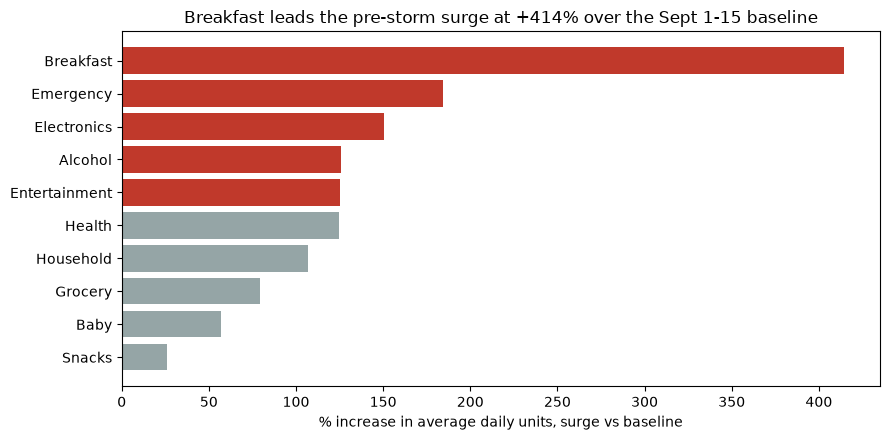

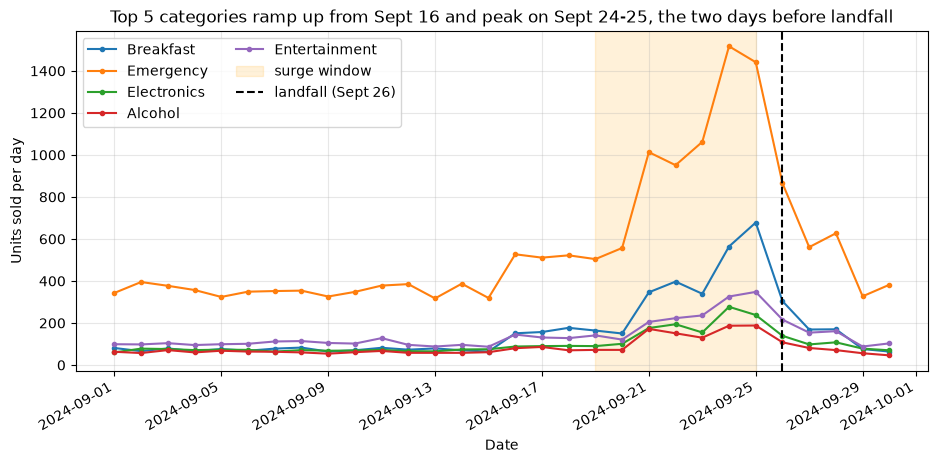

In [12]:
top5 = q1.index[:5].tolist()
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.barh(q1.index[::-1], q1['pct_increase'][::-1], color=['#c0392b' if c in top5 else '#95a5a6' for c in q1.index[::-1]])
ax.set_xlabel('% increase in average daily units, surge vs baseline')
ax.set_title(f"{q1.index[0]} leads the pre-storm surge at +{q1['pct_increase'].iloc[0]:.0f}% over the Sept 1-15 baseline")
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(11, 5))
for c in top5:
    ax.plot(daily_cat.index, daily_cat[c], marker='o', ms=3, label=c)
ax.axvspan(SURGE[0], SURGE[1], color='orange', alpha=.15, label='surge window')
ax.axvline(pd.Timestamp('2024-09-26'), color='k', ls='--', label='landfall (Sept 26)')
ax.set_title('Top 5 categories ramp up from Sept 16 and peak on Sept 24-25, the two days before landfall')
ax.set_xlabel('Date'); ax.set_ylabel('Units sold per day')
ax.legend(ncol=2); ax.grid(alpha=.3); fig.autofmt_xdate(); plt.show()


**Q1 answer:** In the 7 days before landfall Florida stores sold about 2,700 units a day against a 1,100 baseline (2.5x), with Breakfast (Pop-Tarts) rising most at +414% (5.1x) and Emergency supplies adding the most volume (+650 units a day, +184%).

## Question 2: SKU consolidation (the Pop-Tarts effect)

Consolidating SKUs must not change unit totals (asserted below). Before and after for Pop-Tarts:

unit totals unchanged by consolidation: 49584 units | 25402 rows
distinct SKUs: 45 -> canonical products: 20
largest consolidated family: Pop-Tarts Strawberry (4 SKUs)

Pop-Tarts avg daily units: best single SKU 44.4 vs consolidated 166.8 (3.8x)
rank among 45 SKUs, per Pop-Tarts SKU: [8, 12, 17, 18]  |  rank among 20 products, consolidated: 2


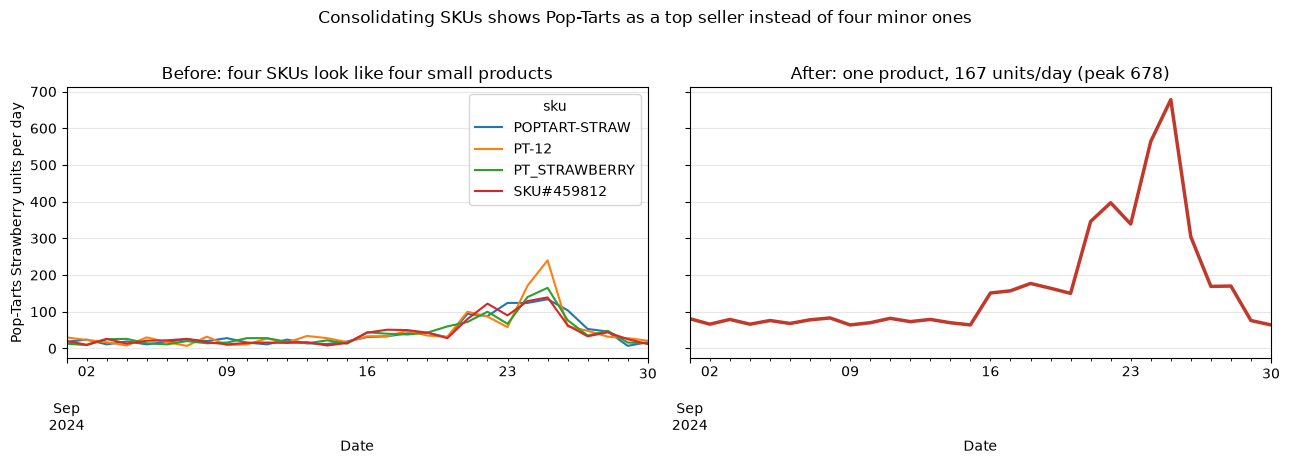

In [13]:
sku_map = build_sku_map(tx_clean)
tx_sku = tx_clean.merge(sku_map, on='sku', how='left')
assert len(tx_sku) == len(tx_clean) and tx_sku['canonical_id'].notna().all()
# consolidation must not change totals
assert tx_sku['quantity'].sum() == tx_clean['quantity'].sum() == tx_sku.groupby('canonical_id')['quantity'].sum().sum()
print('unit totals unchanged by consolidation:', int(tx_sku['quantity'].sum()), 'units |', len(tx_sku), 'rows')
print('distinct SKUs:', tx_sku['sku'].nunique(), '-> canonical products:', tx_sku['canonical_id'].nunique())
sizes = sku_map.groupby('canonical_name').size().sort_values(ascending=False)
print('largest consolidated family:', sizes.index[0], f'({sizes.iloc[0]} SKUs)')

pt_id = sku_map.loc[sku_map['canonical_name'].str.contains('Pop-Tarts'), 'canonical_id'].iloc[0]
pt = tx_sku[(tx_sku['canonical_id'] == pt_id)].dropna(subset=['timestamp']).assign(day=lambda x: x['timestamp'].dt.normalize())
fragmented = pt.groupby(['day', 'sku'])['quantity'].sum().unstack(fill_value=0)
consolidated = pt.groupby('day')['quantity'].sum()

by_sku = tx_sku.groupby('sku')['quantity'].sum().sort_values(ascending=False)
by_prod = tx_sku.groupby('canonical_name')['quantity'].sum().sort_values(ascending=False)
pt_sku_ranks = [int(by_sku.index.get_loc(s)) + 1 for s in fragmented.columns]
print(f'\nPop-Tarts avg daily units: best single SKU {fragmented.mean().max():.1f} vs consolidated {consolidated.mean():.1f} ({consolidated.mean() / fragmented.mean().max():.1f}x)')
print(f'rank among 45 SKUs, per Pop-Tarts SKU: {sorted(pt_sku_ranks)}  |  rank among 20 products, consolidated: {int(by_prod.index.get_loc("Pop-Tarts Strawberry")) + 1}')

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
fragmented.plot(ax=axes[0]); axes[0].set_title('Before: four SKUs look like four small products')
consolidated.plot(ax=axes[1], color='#c0392b', lw=2.5); axes[1].set_title(f'After: one product, {consolidated.mean():.0f} units/day (peak {consolidated.max()})')
for a in axes: a.set_xlabel('Date'); a.grid(alpha=.3)
axes[0].set_ylabel('Pop-Tarts Strawberry units per day')
fig.suptitle('Consolidating SKUs shows Pop-Tarts as a top seller instead of four minor ones', y=1.02)
plt.tight_layout(); plt.show()


**Q2 answer:** Consolidating 45 SKUs into 20 products leaves total units unchanged (49,584) but turns four mid-ranked Pop-Tarts SKUs (ranks 8, 12, 17 and 18, best 44 units/day) into the #2 product overall at 167 units/day, 3.8x its best single SKU. **Business impact:** a buyer looking at the fragmented view would under-stock the second-biggest seller and treat its SKUs as minor lines; after consolidation Pop-Tarts get ordered and pre-positioned as a top-tier product.

## Question 3: Weather correlation

**Data source:** live Open-Meteo call (source column `open-meteo-archive`), no fallback file. Hourly weather (UTC converted to Eastern) is aggregated to store-day and joined to store-day sales. The join must keep every sales row and match each to weather. **n:** 30 days (one storm, one month).

In [14]:
wx_daily = (weather.assign(day=weather['time_local'].dt.normalize())
            .groupby(['store_id', 'day'])
            .agg(max_gust=('wind_gusts_10m', 'max'), mean_wind=('wind_speed_10m', 'mean'),
                 total_precip=('precipitation', 'sum'), min_pressure=('pressure_msl', 'min'))
            .reset_index())
sales_sd = dated.groupby(['store_id', 'day'])['quantity'].sum().rename('units').reset_index()
merged = sales_sd.merge(wx_daily, on=['store_id', 'day'], how='left', validate='one_to_one')
print(f'join rows: sales store-days {len(sales_sd)} -> after join {len(merged)}; unmatched weather: {int(merged["max_gust"].isna().sum())}')
q3_join_rows_preserved = len(merged) == len(sales_sd) and merged['max_gust'].notna().all()
assert q3_join_rows_preserved
merged.head()


join rows: sales store-days 360 -> after join 360; unmatched weather: 0


,store_id,day,units,max_gust,mean_wind,total_precip,min_pressure
0,FL-078,2024-09-01,77,34.6,6.945833,1.5,1011.9
1,FL-078,2024-09-02,103,27.4,4.837500,2.9,1011.9
2,FL-078,2024-09-03,101,35.6,8.066667,8.0,1013.9
3,FL-078,2024-09-04,84,34.2,11.279167,15.6,1016.8
4,FL-078,2024-09-05,90,29.2,5.937500,13.3,1015.4


days in correlation: 30
overall units vs weather (Pearson):
max_gust        0.22
mean_wind       0.29
total_precip   -0.32
min_pressure   -0.24
dtype: float64


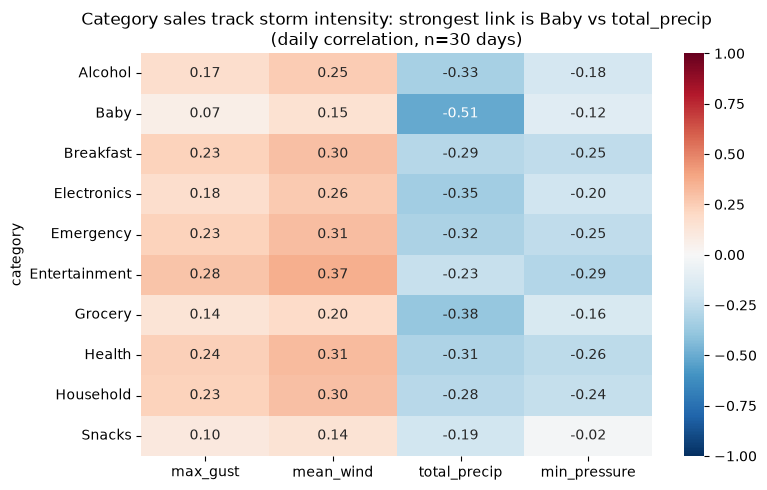

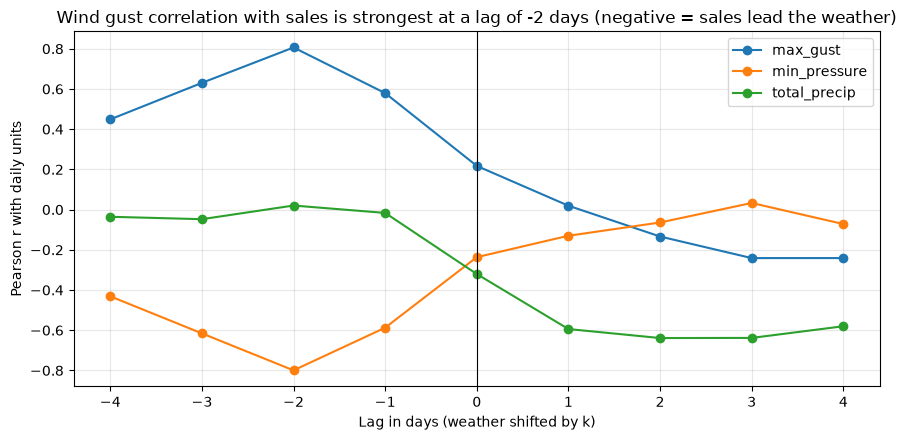

peak wind gust day: 2024-09-26 | peak sales day: 2024-09-25
    max_gust  min_pressure  total_precip
-4      0.45         -0.43         -0.04
-3      0.63         -0.62         -0.05
-2      0.81         -0.80          0.02
-1      0.58         -0.59         -0.02
 0      0.22         -0.24         -0.32
 1      0.02         -0.13         -0.59
 2     -0.13         -0.06         -0.64
 3     -0.24          0.03         -0.64
 4     -0.24         -0.07         -0.58


In [15]:
# statewide daily series: total units vs average-across-stores weather
state = merged.groupby('day').agg(units=('units', 'sum'), max_gust=('max_gust', 'mean'), mean_wind=('mean_wind', 'mean'),
                                  total_precip=('total_precip', 'mean'), min_pressure=('min_pressure', 'mean'))
n_days = len(state)
ind = ['max_gust', 'mean_wind', 'total_precip', 'min_pressure']
print('days in correlation:', n_days)
print('overall units vs weather (Pearson):'); print(state[ind].corrwith(state['units']).round(2))

heat = pd.DataFrame({i: daily_cat.corrwith(state[i]) for i in ind})
top_cell = heat.abs().stack().idxmax()
fig, ax = plt.subplots(figsize=(8, 5))
sns.heatmap(heat, annot=True, fmt='.2f', cmap='RdBu_r', center=0, vmin=-1, vmax=1, ax=ax)
ax.set_title(f'Category sales track storm intensity: strongest link is {top_cell[0]} vs {top_cell[1]}\n(daily correlation, n={n_days} days)')
plt.tight_layout(); plt.show()

# lag: corr(units on day t, weather on day t-k). k>0: weather leads sales; k<0: sales lead weather
lags = range(-4, 5)
lag_corr = pd.DataFrame({i: [state['units'].corr(state[i].shift(k)) for k in lags] for i in ('max_gust', 'min_pressure', 'total_precip')}, index=list(lags))
best = lag_corr['max_gust'].abs().idxmax()
fig, ax = plt.subplots(figsize=(9, 4.5))
lag_corr.plot(ax=ax, marker='o'); ax.axvline(0, color='k', lw=.8)
ax.set_title(f'Wind gust correlation with sales is strongest at a lag of {best:+d} days (negative = sales lead the weather)')
ax.set_xlabel('Lag in days (weather shifted by k)'); ax.set_ylabel('Pearson r with daily units'); ax.grid(alpha=.3)
plt.tight_layout(); plt.show()
print('peak wind gust day:', state['max_gust'].idxmax().date(), '| peak sales day:', state['units'].idxmax().date())
print(lag_corr.round(2))


**Q3 answer, with its caveat:** Same-day correlation is weak (units vs wind gust r=0.22; vs precipitation r=-0.32), but sales lead the wind: units on day t correlate r=0.81 with the average gust two days later, with sales peaking Sept 25 and gusts peaking Sept 26, so buying ramps up one to two days ahead of the worst weather. Caveat: n=30 days from a single storm, both series trend upward so autocorrelation inflates r, the best lag was chosen from nine candidates, and precipitation is negative only because it rained early in the month before the surge.

## Question 4: Store-level geographic patterns

For each store: surge multiple (same windows as Q1) and first day at 2x its own baseline, then compared with distance to an assumed landfall point.

In [16]:
BASELINE = (pd.Timestamp('2024-09-01'), pd.Timestamp('2024-09-15'))   # same windows as Q1
SURGE = (pd.Timestamp('2024-09-19'), pd.Timestamp('2024-09-25'))

units = dated.groupby(['store_id', 'day'])['quantity'].sum().unstack('store_id')
assert units.shape == (30, 12), units.shape          # 30 days x 12 stores, nothing lost in the join
base = units.loc[BASELINE[0]:BASELINE[1]].mean()
surge = units.loc[SURGE[0]:SURGE[1]].mean()
ratio = units / base                                  # each day vs that store's own baseline
after16 = ratio.loc['2024-09-16':]
assert (after16 >= 2).any().all(), 'a store never reached 2x baseline'

q4 = pd.DataFrame({'baseline_avg': base, 'surge_avg': surge, 'multiple': surge / base})
q4['first_day_2x'] = (after16 >= 2).idxmax().dt.date  # first day at or above 2x its own baseline
q4['peak_day'] = units.idxmax().dt.date
q4 = q4.join(stores.set_index('store_id')[['city', 'latitude', 'longitude']])
print('first day any store hit 2x:', q4['first_day_2x'].min(), '| last store to hit it:', q4['first_day_2x'].max())
q4.round(2).sort_values('multiple', ascending=False)


first day any store hit 2x: 2024-09-21 | last store to hit it: 2024-09-22


,baseline_avg,surge_avg,multiple,first_day_2x,peak_day,city,latitude,longitude
store_id,,,,,,,,
FL-330,86.73,235.43,2.71,2024-09-21,2024-09-24,Miami,25.76,-80.19
FL-619,86.13,224.14,2.60,2024-09-21,2024-09-24,Tallahassee,30.44,-84.28
FL-105,91.73,231.71,2.53,2024-09-21,2024-09-25,Tampa,27.95,-82.46
FL-412,89.47,222.86,2.49,2024-09-21,2024-09-25,Jacksonville,30.33,-81.66
FL-302,96.27,239.43,2.49,2024-09-21,2024-09-25,Lakeland,28.04,-81.95
FL-445,94.53,232.00,2.45,2024-09-21,2024-09-24,St. Petersburg,27.77,-82.64
FL-710,93.40,227.86,2.44,2024-09-21,2024-09-25,Pensacola,30.42,-87.22
FL-287,91.07,220.14,2.42,2024-09-21,2024-09-25,Kissimmee,28.29,-81.41
FL-156,94.93,229.14,2.41,2024-09-21,2024-09-24,Daytona Beach,29.21,-81.02


**Reading the table.** Every store crossed 2x its own baseline on Sept 21, except Gainesville (FL-078) on Sept 22. Surge multiples run from 2.23x (Orlando) to 2.71x (Miami). Each store sells only about 90 units a day at baseline, so gaps of a few tenths between stores are small.

surge multiple range: 2.23x - 2.71x | correlation with distance (n=12): r=0.25
outliers (|z| >= 1.5): {'FL-239': {'city': 'Orlando', 'multiple': 2.23}, 'FL-330': {'city': 'Miami', 'multiple': 2.71}}
days to first 2x, by distance rank:
                    city  km_to_landfall first_day_2x
store_id                                             
FL-619       Tallahassee            70.0   2024-09-21
FL-078       Gainesville           154.0   2024-09-22
FL-412      Jacksonville           221.0   2024-09-21
FL-105             Tampa           257.0   2024-09-21
FL-445    St. Petersburg           266.0   2024-09-21
FL-302          Lakeland           279.0   2024-09-21
FL-239           Orlando           286.0   2024-09-21
FL-156     Daytona Beach           287.0   2024-09-21
FL-287         Kissimmee           299.0   2024-09-21
FL-710         Pensacola           324.0   2024-09-21
FL-501        Fort Myers           411.0   2024-09-21
FL-330             Miami           582.0   2024-09-21


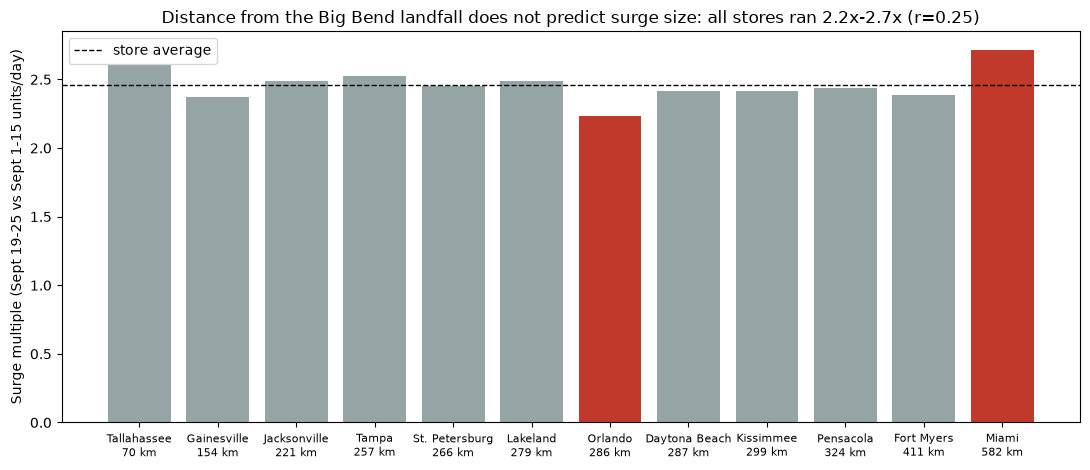

In [17]:
# Assumption: the storm track is represented by one landfall point on the Big Bend coast (approx.), since no track file was supplied.
LANDFALL = (29.9, -83.9)
lat0 = np.radians(LANDFALL[0])
q4['km_to_landfall'] = np.hypot((q4['latitude'] - LANDFALL[0]) * 111,
                                (q4['longitude'] - LANDFALL[1]) * 111 * np.cos(lat0)).round(0)

z = (q4['multiple'] - q4['multiple'].mean()) / q4['multiple'].std()
q4['outlier'] = z.abs() >= 1.5
r = q4['multiple'].corr(q4['km_to_landfall'])
print(f'surge multiple range: {q4["multiple"].min():.2f}x - {q4["multiple"].max():.2f}x | correlation with distance (n=12): r={r:.2f}')
print('outliers (|z| >= 1.5):', q4.loc[q4['outlier'], ['city', 'multiple']].round(2).to_dict('index'))
print('days to first 2x, by distance rank:'); print(q4.sort_values('km_to_landfall')[['city', 'km_to_landfall', 'first_day_2x']].to_string())

ordered = q4.sort_values('km_to_landfall')
fig, ax = plt.subplots(figsize=(11, 4.8))
ax.bar(ordered['city'] + '\n' + ordered['km_to_landfall'].astype(int).astype(str) + ' km', ordered['multiple'],
       color=np.where(ordered['outlier'], '#c0392b', '#95a5a6'))
ax.axhline(q4['multiple'].mean(), color='k', ls='--', lw=1, label='store average')
ax.set_ylabel('Surge multiple (Sept 19-25 vs Sept 1-15 units/day)')
ax.set_title(f'Distance from the Big Bend landfall does not predict surge size: all stores ran {q4["multiple"].min():.1f}x-{q4["multiple"].max():.1f}x (r={r:.2f})')
ax.legend(); plt.xticks(fontsize=8); plt.tight_layout(); plt.show()


**Q4 answer.** No: the stores do not show a geographic pattern. Stores nearer the assumed Big Bend landfall did not spike earlier (11 of 12 hit 2x on Sept 21, including Miami, the farthest at 582 km) or bigger (r=0.25 with distance, if anything slightly the wrong way, n=12). The outliers are Miami (2.71x, high) and Orlando (2.23x, low), and neither is near the landfall point. Caveat: the landfall point is an assumption (no track file was supplied) and the data is synthetic, so small store differences are probably noise.

## Question 5: Signal vs artifact, the board games investigation

Queries the SQLite database with `sqlite3` + pandas, cross-references the transaction CSV, audits SKUs and categories, and checks inventory.

In [18]:
import sqlite3
con = sqlite3.connect(os.path.join(DATA_DIR, 'inventory_and_sales.db'))
print(pd.read_sql("SELECT name, sql FROM sqlite_master WHERE type='table'", con).to_string())

# Problem 1: mixed date formats in daily_sales_summary
print('\ndate string lengths:'); print(pd.read_sql('SELECT length(date) AS len, COUNT(*) AS n FROM daily_sales_summary GROUP BY len', con))
q_week = "SELECT COUNT(*) AS n FROM daily_sales_summary WHERE category = 'Entertainment' AND {col} BETWEEN {a} AND {b}"
naive = pd.read_sql(q_week.format(col='date', a="'2024-09-19'", b="'2024-09-25'"), con)['n'][0]
fixed = pd.read_sql(q_week.format(col="REPLACE(date, '-', '')", a="'20240919'", b="'20240925'"), con)['n'][0]
print(f'Entertainment rows in Sept 19-25 (expect 12 stores x 7 days = 84): naive date filter = {naive}, after normalising = {fixed}')
assert fixed == 84

# Entertainment daily units straight from SQL, dates normalised
ds = pd.read_sql("SELECT REPLACE(date, '-', '') AS d, SUM(total_units) AS units FROM daily_sales_summary "
                 "WHERE category = 'Entertainment' GROUP BY d ORDER BY d", con)
ent_db = ds.assign(day=pd.to_datetime(ds['d'], format='%Y%m%d')).set_index('day')['units']
assert len(ent_db) == 30

def surge_stats(s):
    base = s.loc['2024-09-01':'2024-09-15'].mean()
    return {'baseline_avg': round(base, 1),
            'week_avg_pct': round((s.loc['2024-09-19':'2024-09-25'].mean() / base - 1) * 100, 1),
            'peak_day_pct': round((s.max() / base - 1) * 100, 1), 'peak_day': str(s.idxmax().date())}

good = pd.read_sql("SELECT date, SUM(total_units) AS units FROM daily_sales_summary WHERE category = 'Entertainment' AND length(date) = 10 GROUP BY date", con)
ent_naive = good.assign(day=pd.to_datetime(good['date'])).set_index('day')['units']
print('\nEntertainment surge, SQL totals with dates normalised:', surge_stats(ent_db))
print('Entertainment surge if the 218 YYYYMMDD rows are silently dropped:', surge_stats(ent_naive))


                  name                                                                                                                                                                        sql
0  daily_sales_summary                               CREATE TABLE daily_sales_summary (\n    date TEXT,\n    store_id TEXT,\n    category TEXT,\n    total_units REAL,\n    total_revenue REAL\n)
1     inventory_levels  CREATE TABLE inventory_levels (\n    date TEXT,\n    store_id TEXT,\n    sku TEXT,\n    units_on_hand INTEGER,\n    units_on_order INTEGER,\n    reorder_point INTEGER\n)

date string lengths:
   len     n
0    8   218
1   10  3382
Entertainment rows in Sept 19-25 (expect 12 stores x 7 days = 84): naive date filter = 78, after normalising = 84

Entertainment surge, SQL totals with dates normalised: {'baseline_avg': np.float64(568.5), 'week_avg_pct': np.float64(145.3), 'peak_day_pct': np.float64(271.7), 'peak_day': '2024-09-24'}
Entertainment surge if the 218 YYYYMMDD rows are silent

**What this shows.** The database has its own date artifact: 218 of 3,600 rows use `YYYYMMDD` instead of `YYYY-MM-DD`, so a plain SQL date filter silently loses 6 of the 84 Entertainment rows in the surge week. Fixing it matters little here (week average +145% vs +148% if the rows are dropped). The board-games number also depends on the definition: Entertainment is +145% on a 7-day average but +272% on its single best day (Sept 24), so a "+250%" figure is only reachable as a peak-day number, not a weekly one. Note this is the whole Entertainment category (Monopoly plus playing cards).

In [19]:
# --- same Entertainment surge, DB vs transactions CSV, plus rank among all categories
allcat = pd.read_sql("SELECT REPLACE(date, '-', '') AS d, category, SUM(total_units) AS units FROM daily_sales_summary GROUP BY d, category", con)
allcat['day'] = pd.to_datetime(allcat['d'], format='%Y%m%d')
db_cat = allcat.pivot(index='day', columns='category', values='units')
db_pct = (db_cat.loc[SURGE[0]:SURGE[1]].mean() / db_cat.loc[BASELINE[0]:BASELINE[1]].mean() - 1) * 100
cmp = pd.DataFrame({'db_pct': db_pct, 'csv_pct': q1['pct_increase']}).round(1)
cmp['db_rank'] = cmp['db_pct'].rank(ascending=False).astype(int)
cmp['csv_rank'] = cmp['csv_pct'].rank(ascending=False).astype(int)
print(cmp.sort_values('db_pct', ascending=False))
r_daily = db_cat['Entertainment'].corr(daily_cat['Entertainment'])
print(f"\nEntertainment daily units, DB vs CSV: r={r_daily:.2f}; DB total {db_cat['Entertainment'].sum():.0f} vs CSV total {daily_cat['Entertainment'].sum():.0f} units (different scale, so compare % not levels)")

# --- SKU / category audit on the transactions
sku_map = build_sku_map(tx_clean)
tx_sku = tx_clean.merge(sku_map, on='sku', how='left')
ent = tx_sku[tx_sku['category'] == 'Entertainment']
print('\nSKUs under Entertainment:'); print(ent.groupby(['canonical_name', 'sku']).size())
raw = load_transactions()
print('\nraw category spellings on those SKUs:', raw.loc[raw['sku'].isin(ent['sku'].unique()), 'category'].str.strip().value_counts().to_dict())
# no miscoding: these products appear only under Entertainment, and nothing else sits in Entertainment
assert set(ent['canonical_name']) == {'Board Game - Monopoly', 'Playing Cards'}
assert tx_sku[tx_sku['canonical_name'].isin(ent['canonical_name'].unique())]['category'].eq('Entertainment').all()
print('audit passed: no SKU is miscoded across categories')

prod_daily = (ent.dropna(subset=['timestamp']).assign(day=lambda x: x['timestamp'].dt.normalize())
              .groupby(['day', 'canonical_name'])['quantity'].sum().unstack(fill_value=0))
prod = pd.DataFrame({'baseline_avg': prod_daily.loc[BASELINE[0]:BASELINE[1]].mean(), 'surge_avg': prod_daily.loc[SURGE[0]:SURGE[1]].mean()})
prod['pct_increase'] = (prod['surge_avg'] / prod['baseline_avg'] - 1) * 100
prod['peak_day_pct'] = (prod_daily.max() / prod['baseline_avg'] - 1) * 100   # single best day vs baseline
prod.round(1)


               db_pct  csv_pct  db_rank  csv_rank
category                                         
Breakfast       235.8    414.4        1         1
Emergency       182.6    184.2        2         2
Entertainment   145.3    125.0        3         5
Health          118.6    124.4        4         6
Alcohol         112.0    125.7        5         4
Household       103.9    107.1        6         7
Electronics      97.5    150.3        7         3
Grocery          62.4     79.2        8         8
Baby             54.2     56.9        9         9
Snacks           18.0     25.9       10        10

Entertainment daily units, DB vs CSV: r=0.96; DB total 24070 vs CSV total 4250 units (different scale, so compare % not levels)

SKUs under Entertainment:
canonical_name         sku         
Board Game - Monopoly  BG-MONO         430
                       GAME-MONO       464
                       MONOPOLY-01     439
Playing Cards          CARDS-01        584
                       PLAYCARD-STD 

,baseline_avg,surge_avg,pct_increase,peak_day_pct
canonical_name,,,,
Board Game - Monopoly,42.9,111.4,159.9,315.2
Playing Cards,58.7,117.1,99.4,189.4


**What this shows.** The transactions and the database are consistent in direction and shape: Entertainment daily units correlate at r=0.96, though that is mostly the shared step-up. They do not match exactly: levels differ (24,070 vs 4,250 units, so compare percentages), Entertainment is +145% vs +125%, and it ranks 3rd of 10 categories in the database vs 5th in the transactions, behind Breakfast and Emergency. The audit found no miscoding: Entertainment holds only Monopoly (3 SKUs) and playing cards (2 SKUs), those SKUs never appear under another category, and the four raw category spellings all point to the same SKUs. Both products rose: Monopoly +160% on the weekly average, playing cards +99%; the last column shows each product's single best day vs baseline.

board-game/card stock on hand (window averages): 133 units/store over Sept 12-20 vs 33 over Sept 21-25
share of store-SKUs below reorder point: 0% -> 59%
biggest one-day stock drop: 2024-09-21 | first day DB sales reached 2x baseline: 2024-09-21

inventory SKUs not in the transaction/catalog data: ['LEGACY-PT', 'MISC-001', 'OLD-BATT-50', 'UNKNOWN-99'] = 355 of 4320 rows; inventory has no product names, so their contents cannot be checked; the five board-game/card SKUs themselves are all present


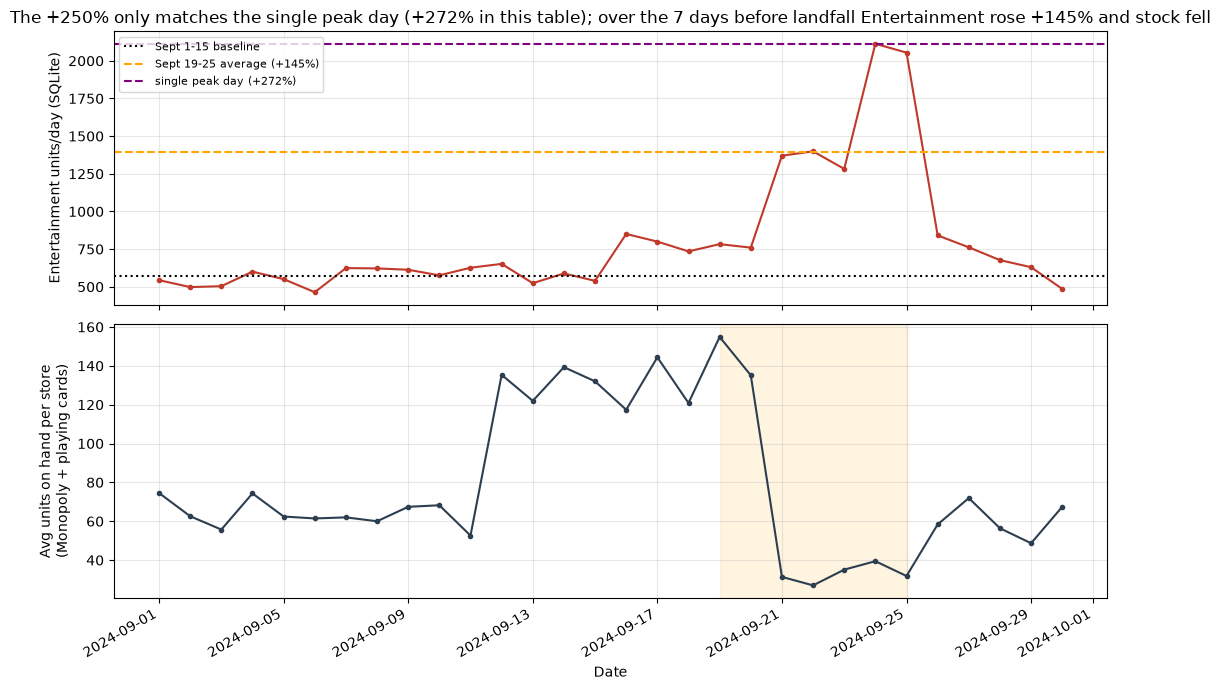

In [20]:
# --- inventory: did stock fall when demand rose, and is any of it a reporting lag?
skus = sku_map.loc[sku_map['canonical_name'].isin(['Board Game - Monopoly', 'Playing Cards']), 'sku'].tolist()
marks = ','.join('?' * len(skus))
inv = pd.read_sql(f'SELECT date, AVG(units_on_hand) AS on_hand, AVG(units_on_hand < reorder_point) AS pct_below_reorder '
                  f'FROM inventory_levels WHERE sku IN ({marks}) GROUP BY date', con, params=skus)
assert inv['date'].str.len().eq(10).all() and len(inv) == 30
assert set(skus) <= set(pd.read_sql('SELECT DISTINCT sku FROM inventory_levels', con)['sku']), 'a board-game/card SKU is missing from inventory'
inv['day'] = pd.to_datetime(inv['date'])
inv = inv.set_index('day')
pre, during = inv.loc['2024-09-12':'2024-09-20'], inv.loc['2024-09-21':'2024-09-25']
print(f"board-game/card stock on hand (window averages): {pre['on_hand'].mean():.0f} units/store over Sept 12-20 vs {during['on_hand'].mean():.0f} over Sept 21-25")
print(f"share of store-SKUs below reorder point: {pre['pct_below_reorder'].mean():.0%} -> {during['pct_below_reorder'].mean():.0%}")
first_big_drop = inv['on_hand'].diff().idxmin().date()
sales_2x = (ent_db.loc['2024-09-16':] >= 2 * ent_db.loc[BASELINE[0]:BASELINE[1]].mean()).idxmax().date()
print('biggest one-day stock drop:', first_big_drop, '| first day DB sales reached 2x baseline:', sales_2x)
assert first_big_drop == sales_2x, 'stock and sales moved on different days (possible reporting lag)'

known = set(sku_map['sku'])
inv_sku = pd.read_sql('SELECT sku, COUNT(*) AS n FROM inventory_levels GROUP BY sku', con)
unmapped = inv_sku[~inv_sku['sku'].isin(known)]
print(f"\ninventory SKUs not in the transaction/catalog data: {unmapped['sku'].tolist()} = {unmapped['n'].sum()} of {inv_sku['n'].sum()} rows; inventory has no product names, so their contents cannot be checked; the five board-game/card SKUs themselves are all present")

wk, pk = surge_stats(ent_db)['week_avg_pct'], surge_stats(ent_db)['peak_day_pct']
fig, (a1, a2) = plt.subplots(2, 1, figsize=(11, 7), sharex=True)
a1.plot(ent_db.index, ent_db, marker='o', ms=3, color='#c0392b')
b = ent_db.loc[BASELINE[0]:BASELINE[1]].mean()
a1.axhline(b, color='k', ls=':', label='Sept 1-15 baseline')
a1.axhline(b * (1 + wk / 100), color='orange', ls='--', label=f'Sept 19-25 average (+{wk:.0f}%)')
a1.axhline(ent_db.max(), color='purple', ls='--', label=f'single peak day (+{pk:.0f}%)')
a1.set_ylabel('Entertainment units/day (SQLite)')
a1.set_title(f'The +250% only matches the single peak day (+{pk:.0f}% in this table); over the 7 days before landfall Entertainment rose +{wk:.0f}% and stock fell')
a1.legend(fontsize=8); a1.grid(alpha=.3)
a2.plot(inv.index, inv['on_hand'], marker='o', ms=3, color='#2c3e50')
a2.set_ylabel('Avg units on hand per store\n(Monopoly + playing cards)'); a2.set_xlabel('Date'); a2.grid(alpha=.3)
a2.axvspan(SURGE[0], SURGE[1], color='orange', alpha=.12)
fig.autofmt_xdate(); plt.tight_layout(); plt.show()


**Q5 answer and recommendation.** The rise is real demand, not a data artifact, but smaller than +250% on a weekly basis. The evidence: (1) a "+250%" is only reachable as a single-best-day figure for the whole Entertainment category, while the 7-day increase is +145% (database) or +125% (transactions), and Monopoly alone is +160%; (2) the two sources are consistent in direction and shape (r=0.96, mostly the shared step-up); (3) no SKU is miscoded, and both products rose; (4) board-game and card stock on hand averaged 133 units per store over Sept 12-20 and 33 over Sept 21-25, the largest one-day stock drop fell on Sept 21, the same day sales first reached 2x baseline, and 59% of store-SKUs were below their reorder point in the second window vs 0% in the first, so there is no reporting lag longer than one day (inventory is a once-a-day snapshot, so nothing finer can be ruled out); (5) the mixed date formats move the weekly figure only from +145% to +148%, and four inventory SKUs (355 of 4,320 rows) have no names so their contents cannot be checked, but all five board-game/card SKUs are present.

**Recommendation:** yes, stock extra board games for the next storm, sized for roughly 2.3-2.6x normal demand over the pre-landfall week (Entertainment +125% to +145%, Monopoly alone +160%), not 3.5x, and after Breakfast and Emergency supplies in priority. Demand started rising on Sept 16 and stepped up sharply on Sept 21, so stock should be on shelves by about Sept 16, roughly ten days before landfall, and certainly by Sept 21. Confidence limits: this is one storm, one month of synthetic data, and inventory has only daily snapshots.

## Reflection

**1. Data quality impact.** The Pop-Tarts SKU split mattered most. Raw, the best single SKU averaged 44.4 units a day and ranked 8th of 45, but after merging the four SKUs it is 166.8 units a day and the #2 product out of 20, about 3.8x higher. If I had not caught it I would have treated Pop-Tarts as a minor product and under-stocked it.

**2. ETL trade-offs.** I dropped the 130 rows with negative quantities instead of flipping them to positive, because nothing in the data says they are returns or typos. Flipping them would have added back well under 1% more units, so the totals and surge numbers would barely move. I would make the same call again since dropping does not make up data, but I would write down that it is a judgement call. The bigger call was leaving the 881 rows with no timestamp out of the date-based numbers instead of guessing their dates.

**3. Pipeline trust.** First I would check the row counts at every step, and that is already in the notebook through the decision log and the asserts (25,562 rows down to 25,402, and 360 store-days before and after the weather join). What is not in there is a check on how much the answers depend on my choices, like the Sept 1-15 baseline window and the 881 rows with no timestamp. The most fragile part was the weather join and the date handling, since a timezone or date-format slip would quietly shift every number.

**4. Business vs data.** For board games I recommend stocking extra, sized for about 2.3-2.6x normal demand over the pre-landfall week and not the +250% headline, which only shows up as a single peak-day figure. The data supports that the rise is real (the two sources are consistent in direction and stock fell the same day sales jumped), but it is one storm and one month of synthetic data. I would tell a buyer to plan around the weekly number and not the peak day. With more time or data I would check a second storm, because one storm cannot tell me how much of this repeats.

**5. Team collaboration.** I worked alone, so I did the cleaning, the API, the analysis and the charts myself, and nobody reviewed my code, so my own asserts were the reviewer. The biggest time cost was starting late and leaving the last questions and the reflection to the end. With another week I would start earlier, commit small pieces as I go, and add a check on how sensitive the surge numbers are to the baseline window. The most valuable thing I did was check every step with row-count asserts.